# 02 Preprocess SAROS into training slices

Input: `raw/data/case_XXX/` (CT + mask) and `raw/saros_subset.csv` from notebook 01.

Output in `ct-body-comp/processed/` (v1) or `processed_v2/` (v2):
- one `case_XXX.npz` per case: `image` (slices × H × W, raw HU, int16), `label` (same shape, our class ids, 255 = ignore), `z` (original slice numbers), `spacing` (mm)
- `index.csv`: one row per case with slice count, spacing, collection and train/test set

All slices are stored in **radiological orientation** (anterior at top, patient's right on viewer's left).

**Versions.** `VERSION = 'v1'` reproduces the first run (mediastinum and pericardium treated as background). `VERSION = 'v2'` adds a **mediastinum** class (SAROS labels 7 + 9), after the v1 error analysis showed pericardial fat at the diaphragm being mislabelled as abdominal cavity. v2 writes to `*_v2/` folders, so v1 results stay untouched for comparison.

In [ ]:
# setup
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json
import numpy as np, pandas as pd, nibabel as nib
import matplotlib.pyplot as plt

ROOT = '/content/drive/MyDrive/ct-body-comp'
RAW  = f'{ROOT}/raw'
DATA = f'{RAW}/data'
VERSION = 'v2'   # v1 = first run (mediastinum/pericardium as background); v2 = adds a mediastinum class
SUFFIX = '' if VERSION == 'v1' else f'_{VERSION}'
OUT  = f'{ROOT}/processed{SUFFIX}'   # v2 writes to processed_v2/, so v1 stays untouched for comparison
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


**Classes we keep.** Muscle, SAT and abdominal cavity are the core; thoracic cavity (chest CT, Phase 2) and bone (bone density) are kept too; v2 adds mediastinum. Everything else becomes background.

We store **raw HU**, not normalized values, because VAT is computed later from HU (−190 to −30) inside the cavity.

In [ ]:
# settings
# SAROS label -> our class. Anything not listed becomes 0 (background). 255 stays 255 (= ignore).
CLASS_MAP = {1: 1,   # subcutaneous fat
             2: 2,   # muscle
             3: 3,   # abdominal cavity (VAT is derived later: fat HU inside this)
             4: 4,   # thoracic cavity (needed for chest CT, e.g. NLST in Phase 2)
             5: 5}   # bone
CLASS_NAMES = ['background', 'subcutaneous', 'muscle', 'abdominal cavity', 'thoracic cavity', 'bone']
if VERSION == 'v2':
    # v1 error analysis: pericardial/mediastinal fat at the diaphragm was mislabelled as abdominal cavity,
    # because the model had never been taught it was its own region. SAROS 7 = pericardium, 9 = mediastinum.
    CLASS_MAP.update({7: 6, 9: 6})
    CLASS_NAMES = CLASS_NAMES + ['mediastinum']
IGNORE = 255
HU_MIN, HU_MAX = -1024, 3071   # only to remove junk values (e.g. -3000); real windowing happens at training

In [ ]:
# which cases do we have?
info = pd.read_csv(f'{RAW}/saros_subset.csv')
info['has_ct'] = info['id'].apply(lambda c: os.path.exists(f'{DATA}/{c}/image.nii.gz'))
print('split values:', info['split'].value_counts().to_dict())
print(f"cases with CT: {info['has_ct'].sum()} of {len(info)}")
cases = info[info['has_ct']].reset_index(drop=True)

split values: {'fold-5': 11, 'test': 10, 'fold-3': 8, 'fold-4': 7, 'fold-2': 7, 'fold-1': 7}
cases with CT: 47 of 50


In [ ]:
# helper functions
def to_display(vol_slice):
    """RAS (x=left->right, y=post->ant) slice -> radiological view: anterior at top, patient's right on viewer's left."""
    return vol_slice.T[::-1, ::-1]

def remap(seg):
    out = np.zeros_like(seg, dtype=np.uint8)
    for src, dst in CLASS_MAP.items():
        out[seg == src] = dst
    out[seg == IGNORE] = IGNORE
    return out

def process_case(case_id):
    ct  = nib.as_closest_canonical(nib.load(f'{DATA}/{case_id}/image.nii.gz'))
    seg = nib.as_closest_canonical(nib.load(f'{DATA}/{case_id}/body-regions.nii.gz'))
    img = np.asarray(ct.dataobj, dtype=np.float32)
    lab = np.asarray(seg.dataobj).astype(np.int16)
    assert img.shape == lab.shape, f'{case_id}: shape mismatch {img.shape} vs {lab.shape}'
    sx, sy, sz = [float(v) for v in ct.header.get_zooms()[:3]]

    # keep slices that were actually annotated (not entirely 255) and contain some tissue label
    keep = [z for z in range(lab.shape[2])
            if not (lab[:, :, z] == IGNORE).all() and (lab[:, :, z] > 0).any()]
    images = np.stack([to_display(np.clip(img[:, :, z], HU_MIN, HU_MAX)) for z in keep]).astype(np.int16)
    labels = np.stack([to_display(remap(lab[:, :, z])) for z in keep]).astype(np.uint8)
    np.savez_compressed(f'{OUT}/{case_id}.npz', image=images, label=labels,
                        z=np.array(keep), spacing=np.array([sx, sy, sz]))
    return dict(id=case_id, n_slices=len(keep), height=images.shape[1], width=images.shape[2],
                spacing_x=sx, spacing_y=sy, spacing_z=sz)

Takes a few minutes (reading from Drive is the slow part).

In [ ]:
# run over all cases
rows, failed = [], []
for cid in cases['id']:
    try:
        rows.append(process_case(cid)); print('ok  ', cid, rows[-1]['n_slices'], 'slices')
    except Exception as e:
        failed.append(cid); print('FAIL', cid, e)

index = pd.DataFrame(rows).merge(cases[['id', 'split', 'tcia_collection', 'anatomic_region']], on='id')
index['set'] = np.where(index['split'].astype(str).str.lower().str.contains('test'), 'test', 'train')
index.to_csv(f'{OUT}/index.csv', index=False)
print(f'\nprocessed {len(index)} cases, {index.n_slices.sum()} slices | failed: {failed}')
print(index.groupby('set').n_slices.agg(['count', 'sum']).rename(columns={'count': 'cases', 'sum': 'slices'}))
print('image sizes:', index.groupby(['height', 'width']).size().to_dict())

ok   case_000 20 slices
ok   case_001 10 slices
ok   case_002 21 slices
ok   case_003 11 slices
ok   case_004 20 slices
ok   case_005 16 slices
ok   case_006 19 slices
ok   case_007 21 slices
ok   case_008 20 slices
ok   case_009 12 slices
ok   case_010 9 slices
ok   case_012 14 slices
ok   case_013 13 slices
ok   case_014 17 slices
ok   case_015 19 slices
ok   case_016 16 slices
ok   case_017 12 slices
ok   case_018 17 slices
ok   case_021 15 slices
ok   case_022 20 slices
ok   case_023 17 slices
ok   case_024 12 slices
ok   case_025 20 slices
ok   case_026 20 slices
ok   case_027 18 slices
ok   case_028 19 slices
ok   case_029 19 slices
ok   case_030 21 slices
ok   case_031 8 slices
ok   case_032 21 slices
ok   case_033 19 slices
ok   case_034 15 slices
ok   case_035 10 slices
ok   case_036 19 slices
ok   case_037 18 slices
ok   case_038 25 slices
ok   case_039 21 slices
ok   case_040 10 slices
ok   case_041 12 slices
ok   case_042 18 slices
ok   case_043 14 slices
ok   case_044 13 s

In [ ]:
# class balance (what fraction of labelled pixels is each class?)
counts = np.zeros(len(CLASS_NAMES), dtype=np.int64)
for cid in index['id']:
    lab = np.load(f'{OUT}/{cid}.npz')['label']
    counts += np.bincount(lab[lab != IGNORE].ravel(), minlength=len(CLASS_NAMES))[:len(CLASS_NAMES)]
for name, c in zip(CLASS_NAMES, counts):
    print(f'{name:18s} {100 * c / counts.sum():5.1f}%')

background          48.0%
subcutaneous        19.6%
muscle              11.1%
abdominal cavity    14.2%
thoracic cavity      2.7%
bone                 3.2%
mediastinum          1.2%


Check: anterior abdominal wall at the **top**, table at the **bottom**, colours on the right tissues.

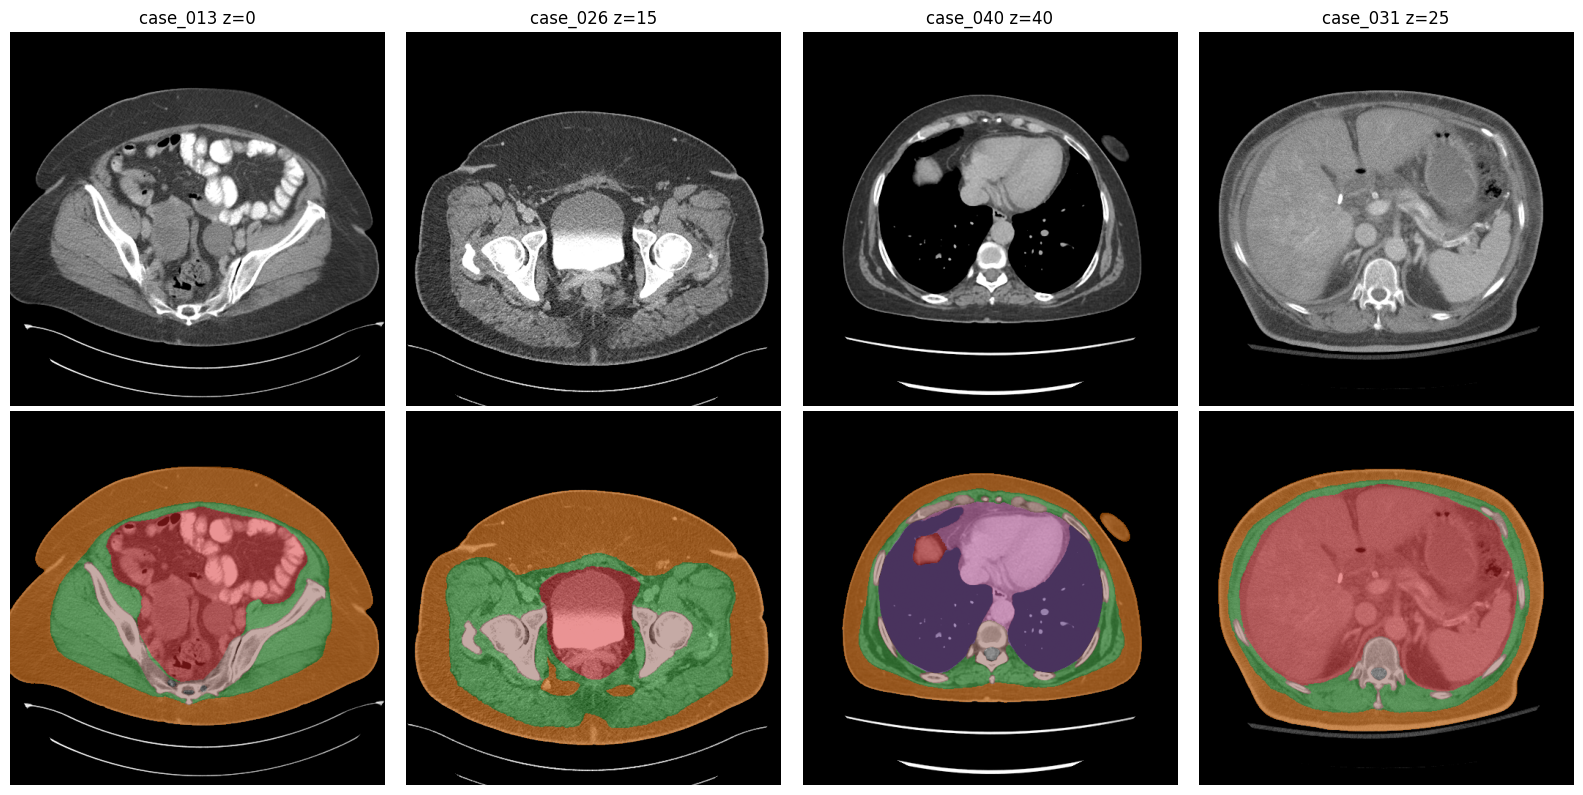

In [ ]:
# visual check of 4 random slices (should look like a radiology viewer now)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for k, cid in enumerate(rng.choice(index['id'], size=min(4, len(index)), replace=False)):
    d = np.load(f'{OUT}/{cid}.npz'); i = rng.integers(len(d['z']))
    im, lb = d['image'][i], d['label'][i]
    axes[0, k].imshow(np.clip(im, -200, 250), cmap='gray'); axes[0, k].set_title(f'{cid} z={d["z"][i]}')
    axes[1, k].imshow(np.clip(im, -200, 250), cmap='gray')
    axes[1, k].imshow(np.ma.masked_where((lb == 0) | (lb == IGNORE), lb), cmap='tab10', vmin=0, vmax=9, alpha=0.5)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()